##**Text Preprocessing**

In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter
from nltk.stem import PorterStemmer
from wordcloud import WordCloud
from nltk.stem import WordNetLemmatizer

# Downloads
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
# 1. Understand Text Data

# Load & Select Text
mental_health_data = pd.read_csv('/content/sample_data/Combined Data.csv')

sample_df = mental_health_data.sample(20000, random_state=42) # real raw text
text_series = sample_df['statement']

print(text_series.shape)
print(text_series)

(20000,)
22261    Just as the the title says. I feel like one is...
41400    a blackened sky encroached tugging behind it m...
20065    It gives you insomnia, which in turn makes you...
30036    Hello all, I'm a new submitter to this channel...
780                       Thank God the CB is over for Eid
                               ...                        
26981    that is it, right?I mean, I deserve this pain....
46815    Weight gain making me depressed. Any tips? I h...
15018    my dog is the only reason i have not killed my...
18700    I would been feeling really good lately! Meds ...
49552                                                  NaN
Name: statement, Length: 20000, dtype: object


In [ ]:
# Select one review
# اختيار أول نص من العينة لعرضه
text = sample_df['statement'].iloc[0]
print(text)

Just as the the title says. I feel like one is hyper alot, a attention whore, and is idealistic and stupid. and the other is calm, trys to be normal, is a realist, and wants to kill the other one, witch is why I somtimes choke myself, usually for at most 30 seconds at a time just so the other can stop controlling me and make me look like an idiot. And I am not insane, its not like there telling me to hurt others, So can some please tell me, is this normal? Am I depressed? Or is it some other mental disease. Thanks I feel like there is 2 of me and one of them hates the other


In [ ]:
# 2. Text Cleaning

# a. Normalize text
text = sample_df['statement'].str.lower()
print(text)

22261    just as the the title says. i feel like one is...
41400    a blackened sky encroached tugging behind it m...
20065    it gives you insomnia, which in turn makes you...
30036    hello all, i'm a new submitter to this channel...
780                       thank god the cb is over for eid
                               ...                        
26981    that is it, right?i mean, i deserve this pain....
46815    weight gain making me depressed. any tips? i h...
15018    my dog is the only reason i have not killed my...
18700    i would been feeling really good lately! meds ...
49552                                                  NaN
Name: statement, Length: 20000, dtype: object


In [ ]:
# b. Remove punctuation
text = text.str.replace(r'[^\w\s]', '', regex=True) # Remove punctuation -> remove noise

print(text)

22261    just as the the title says i feel like one is ...
41400    a blackened sky encroached tugging behind it m...
20065    it gives you insomnia which in turn makes your...
30036    hello all im a new submitter to this channel i...
780                       thank god the cb is over for eid
                               ...                        
26981    that is it righti mean i deserve this pain i m...
46815    weight gain making me depressed any tips i hav...
15018    my dog is the only reason i have not killed my...
18700    i would been feeling really good lately meds a...
49552                                                  NaN
Name: statement, Length: 20000, dtype: object


In [ ]:
# c. Remove stopwords

stop_words = set(stopwords.words('english')) # Remove stopwords -> To keep important words

text = text.fillna('') # Handle NaN values by converting them to empty strings
text = text.apply(
    lambda x: " ".join([word for word in x.split() if word not in stop_words])
)

print(text)

22261    title says feel like one hyper alot attention ...
41400    blackened sky encroached tugging behind depres...
20065    gives insomnia turn makes depression worse day...
30036    hello im new submitter channel went nights ago...
780                                       thank god cb eid
                               ...                        
26981    righti mean deserve pain must want id try esca...
46815    weight gain making depressed tips lithium cita...
15018                               dog reason killed well
18700    would feeling really good lately meds effectiv...
49552                                                     
Name: statement, Length: 20000, dtype: object


In [ ]:
from nltk.tokenize import sent_tokenize

# 3. Tokenization

#Word Tokens
tokens = text.apply(word_tokenize)

#Sentence Tokens
sentences = text.apply(sent_tokenize)

#Output Comparison
print("  Word vs Sentence Tokenization Comparison")
comparison = pd.DataFrame({
    'Word Tokens': tokens.head(),
    'Sentence Tokens': sentences.head()})
print(comparison)

  Word vs Sentence Tokenization Comparison
                                             Word Tokens  \
22261  [title, says, feel, like, one, hyper, alot, at...   
41400  [blackened, sky, encroached, tugging, behind, ...   
20065  [gives, insomnia, turn, makes, depression, wor...   
30036  [hello, im, new, submitter, channel, went, nig...   
780                                [thank, god, cb, eid]   

                                         Sentence Tokens  
22261  [title says feel like one hyper alot attention...  
41400  [blackened sky encroached tugging behind depre...  
20065  [gives insomnia turn makes depression worse da...  
30036  [hello im new submitter channel went nights ag...  
780                                   [thank god cb eid]  


In [ ]:
# 4. Stemming / Lemmatization

# Stemming
# Reduce words to root form

stemmer = PorterStemmer()

tokens_stemmed = tokens.apply(lambda x: [stemmer.stem(word) for word in x])

print(tokens_stemmed.head())

22261    [titl, say, feel, like, one, hyper, alot, atte...
41400       [blacken, sky, encroach, tug, behind, depress]
20065    [give, insomnia, turn, make, depress, wors, da...
30036    [hello, im, new, submitt, channel, went, night...
780                                  [thank, god, cb, eid]
Name: statement, dtype: object


In [ ]:
# Lemmatization
lemmatizer = WordNetLemmatizer()

tokens_lemma = tokens.apply(lambda x: [lemmatizer.lemmatize(word) for word in x])

print(tokens_lemma.head())

22261    [title, say, feel, like, one, hyper, alot, att...
41400    [blackened, sky, encroached, tugging, behind, ...
20065    [give, insomnia, turn, make, depression, worse...
30036    [hello, im, new, submitter, channel, went, nig...
780                                  [thank, god, cb, eid]
Name: statement, dtype: object


In [ ]:
# Most Frequent Words

from collections import Counter

all_words = []

for words in tokens_lemma:
    all_words.extend(words)

word_counts = Counter(all_words)

common_words = word_counts.most_common(10) # Find most important words

words = [w[0] for w in common_words]
counts = [w[1] for w in common_words]

common_words

[('like', 14579),
 ('feel', 13364),
 ('want', 10959),
 ('know', 9223),
 ('get', 8650),
 ('life', 8548),
 ('im', 8242),
 ('time', 8003),
 ('even', 6923),
 ('can', 6677)]

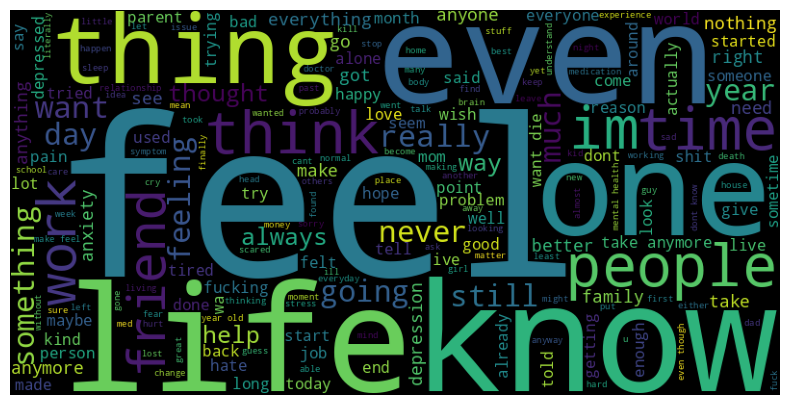

In [ ]:
# Word Cloud
# Visualize frequent terms

# تجميع كل الكلمات من كل النصوص في متغير واحد
all_words = [word for tokens in tokens_lemma for word in tokens]
text_all = " ".join(all_words)

wc = WordCloud(width=800, height=400, background_color='black').generate(text_all)

plt.figure(figsize=(10, 5))
plt.imshow(wc)
plt.axis('off')
plt.show()